# SafeStep · 2 — Feature cleaning, ranking & selection
`345 features` → `remove constant/duplicate` → `6 rankings (2 tasks × 3 methods)` → `correlation filter` → `best k` → `family ablation`

Uses **train** subjects to rank and **validation** subjects to choose. The test set is not touched.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os, sys, json, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.feature_selection import mutual_info_classif, f_classif
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, f1_score
from scipy.stats import rankdata, spearmanr

BASE = '/content/drive/MyDrive/Daffodil Robo Tech Olympiad'
PROJ = f'{BASE}/SafeStep'
D = {k: f'{PROJ}/{k}' for k in ['data', 'artifacts', 'figures', 'models', 'code']}
SEED = 42
rng = np.random.default_rng(SEED)
sns.set_theme(style='whitegrid'); plt.rcParams['figure.dpi'] = 110
def save_fig(name): plt.savefig(f"{D['figures']}/{name}.png", dpi=300, bbox_inches='tight')

F  = pd.read_parquet(f"{D['data']}/features_345.parquet").set_index('win_id')
wm = pd.read_parquet(f"{D['data']}/windows_meta.parquet").set_index('win_id')
cat = pd.read_csv(f"{D['artifacts']}/feature_catalog.csv").set_index('feature')
assert (F.index == wm.index).all()
print(F.shape, wm.shape)

(136051, 345) (136051, 19)


## 1 · Task masks

In [3]:
TASKS = {
    'fall':     dict(col='y_fall',     valid=lambda m: m.y_fall >= 0),
    'activity': dict(col='y_activity', valid=lambda m: m.y_activity != 'ignore'),
}
def mask(split, task):
    return ((wm.split == split) & TASKS[task]['valid'](wm)).values
def labels(m, task):
    return wm[TASKS[task]['col']].values[m]
def sample_idx(m, y, n=40000):
    # stratified sample (keeps every class, caps the big ones)
    idx = np.where(m)[0]
    if len(idx) <= n: return idx
    out = []
    classes, counts = np.unique(y, return_counts=True)
    per = max(n // len(classes), 1)
    for c in classes:
        ci = idx[y == c]
        out.append(rng.choice(ci, size=min(len(ci), per), replace=False))
    return np.sort(np.concatenate(out))
for t in TASKS:
    for s in ['train', 'val', 'test']:
        m = mask(s, t); print(f'{t:9s} {s:5s} {m.sum():7d}', dict(zip(*np.unique(labels(m, t), return_counts=True))) if t == 'fall' else '')

fall      train   54257 {np.int64(0): np.int64(50065), np.int64(1): np.int64(4192)}
fall      val     18353 {np.int64(0): np.int64(17153), np.int64(1): np.int64(1200)}
fall      test    25689 {np.int64(0): np.int64(23889), np.int64(1): np.int64(1800)}
activity  train   65666 
activity  val     22128 
activity  test    30892 


## 2 · Clean: constant & duplicate features (train only)

In [4]:
tr_any = (wm.split == 'train').values
Ftr = F.values[tr_any]
const = [c for c, s in zip(F.columns, Ftr.std(0)) if s < 1e-9]
keep = [c for c in F.columns if c not in const]
# exact duplicates: identical values on every train window
hashes = {}
dups = {}
for c in keep:
    h = hash(np.round(F[c].values[tr_any], 6).tobytes())
    if h in hashes and np.allclose(F[c].values[tr_any], F[hashes[h]].values[tr_any]):
        dups[c] = hashes[h]
    else:
        hashes[h] = c
CLEAN = [c for c in keep if c not in dups]
print(f'constant: {const}')
print(f'duplicates removed ({len(dups)}):'); [print(f'   {k}  ==  {v}') for k, v in dups.items()]
print(f'\n{len(F.columns)} → {len(CLEAN)} unique features '
      f'({sum(cat.loc[c, "frame"] == "invariant" for c in CLEAN)} phone-ready)')

constant: ['tilt__argmin']
duplicates removed (4):
   fall__peak_svm  ==  svm__max
   fall__peak_pos  ==  svm__argmax
   fall__tilt_max  ==  tilt__max
   fall__gyro_peak  ==  gyro__max

345 → 340 unique features (274 phone-ready)


## 3 · Six rankings: (fall, activity) × (mutual information, ANOVA F, Extra-Trees)

In [5]:
ranks, scores = {}, {}
for task in TASKS:
    m = mask('train', task); y_all = labels(m, task)
    idx = sample_idx(m, y_all, 40000)
    X = F[CLEAN].values[idx]; y = wm[TASKS[task]['col']].values[idx]
    t0 = time.time()
    s_mi = mutual_info_classif(X, y, random_state=SEED)
    s_f, _ = f_classif(X, y); s_f = np.nan_to_num(s_f)
    et = ExtraTreesClassifier(n_estimators=200, max_features='sqrt', min_samples_leaf=2,
                              class_weight='balanced', n_jobs=-1, random_state=SEED).fit(X, y)
    for name, s in [('mi', s_mi), ('anova', s_f), ('trees', et.feature_importances_)]:
        scores[f'{task}_{name}'] = s
        ranks[f'{task}_{name}'] = rankdata(-s, method='average')
    print(f'{task:9s} ranked on {len(idx)} windows in {time.time()-t0:.0f}s')

R = pd.DataFrame(ranks, index=CLEAN)
R['consensus'] = R.mean(1)
R = R.sort_values('consensus')
R['frame'] = cat.loc[R.index, 'frame'].values
R['group'] = cat.loc[R.index, 'group'].values
R.head(15)

fall      ranked on 24192 windows in 47s
activity  ranked on 38649 windows in 98s


,fall_mi,fall_anova,fall_trees,activity_mi,activity_anova,activity_trees,consensus,frame,group
fall__tilt_rate_max,16.0,8.0,20.0,53.0,18.0,7.0,20.333333,invariant,fall_dynamics
vert__max,3.0,25.0,11.0,3.0,69.0,28.0,23.166667,invariant,statistical
fall__peak_drop,10.0,26.0,12.0,22.0,52.0,34.0,26.000000,invariant,fall_dynamics
tilt__max,35.0,3.5,2.0,109.0,13.0,6.0,28.083333,invariant,statistical
dyn__max,2.0,20.0,27.0,11.0,53.0,59.0,28.666667,invariant,statistical
tilt__range,36.0,3.5,1.0,110.0,14.0,8.0,28.750000,invariant,statistical
tilt__d1_mean,31.0,10.0,10.0,103.0,12.0,11.0,29.500000,invariant,temporal
tilt__p95,33.0,2.0,7.0,111.0,15.0,13.0,30.166667,invariant,statistical
ay__p95,22.0,39.0,13.0,43.0,64.0,4.0,30.833333,device,device_axis
tilt__rms,34.0,1.0,6.0,120.0,23.0,12.0,32.666667,invariant,statistical


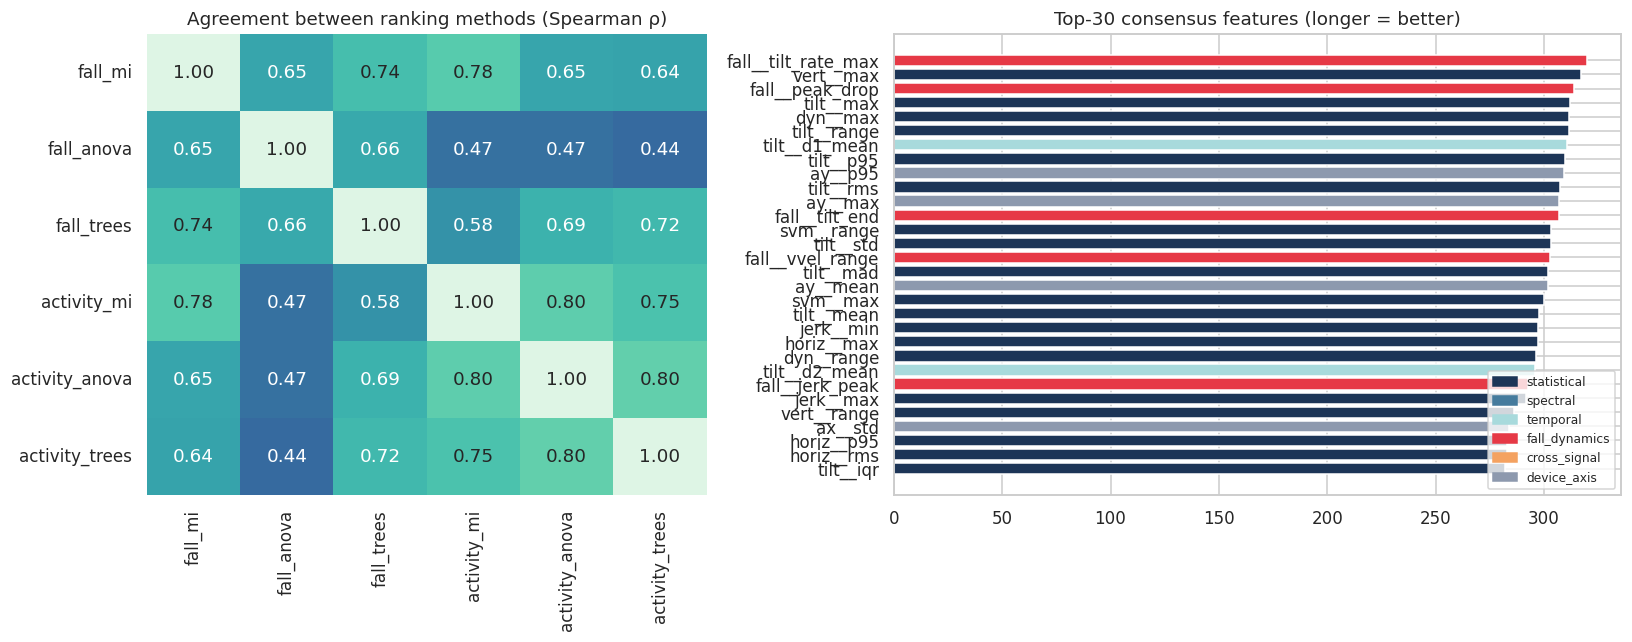

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [1, 1.3]})
cols = [c for c in R.columns if c.startswith(('fall_', 'activity_'))]
rho = pd.DataFrame(spearmanr(R[cols]).statistic, index=cols, columns=cols)
sns.heatmap(rho, annot=True, fmt='.2f', cmap='mako', vmin=0, vmax=1, ax=ax[0], cbar=False)
ax[0].set_title('Agreement between ranking methods (Spearman ρ)')
top = R.head(30)
pal = {'statistical': '#1d3557', 'spectral': '#457b9d', 'temporal': '#a8dadc',
       'fall_dynamics': '#e63946', 'cross_signal': '#f4a261', 'device_axis': '#8d99ae'}
ax[1].barh(top.index[::-1], (len(CLEAN) - top.consensus[::-1]), color=[pal[g] for g in top.group[::-1]])
ax[1].set_title('Top-30 consensus features (longer = better)')
from matplotlib.patches import Patch
ax[1].legend(handles=[Patch(color=v, label=k) for k, v in pal.items()], fontsize=8, loc='lower right')
plt.tight_layout(); save_fig('20_ranking_consensus'); plt.show()

## 4 · Correlation filter (|r| < 0.95, best-ranked feature wins)

In [7]:
CORR_THR = 0.95
si = sample_idx((wm.split == 'train').values, wm.y_activity.values[(wm.split == 'train').values], 25000)
C = np.abs(np.corrcoef(F.loc[F.index[si], R.index].values, rowvar=False))
C = np.nan_to_num(C)
pos = {f: i for i, f in enumerate(R.index)}

def decorrelated(order):
    kept = []
    for f in order:
        if all(C[pos[f], pos[k]] < CORR_THR for k in kept):
            kept.append(f)
    return kept

ORDER_ALL   = decorrelated(list(R.index))
ORDER_PHONE = decorrelated([f for f in R.index if R.loc[f, 'frame'] == 'invariant'])
print(f'after |r|<{CORR_THR}: all={len(ORDER_ALL)}  phone-ready={len(ORDER_PHONE)}')

after |r|<0.95: all=277  phone-ready=215


## 5 · How many features? (validation subjects)

In [8]:
try:
    import lightgbm as lgb
    def make_model(seed=SEED):
        return lgb.LGBMClassifier(n_estimators=150, learning_rate=0.1, num_leaves=31, subsample=0.8,
                                  subsample_freq=1, colsample_bytree=0.8, class_weight='balanced',
                                  n_jobs=-1, random_state=seed, verbose=-1)
    print('evaluator: LightGBM')
except ImportError:
    def make_model(seed=SEED):
        return HistGradientBoostingClassifier(max_iter=150, learning_rate=0.1, class_weight='balanced', random_state=seed)
    print('evaluator: HistGradientBoosting')

def fit_eval(cols, task, n_train=40000, seed=SEED):
    mtr, mva = mask('train', task), mask('val', task)
    idx = sample_idx(mtr, labels(mtr, task), n_train)
    Xtr, ytr = F[cols].values[idx], wm[TASKS[task]['col']].values[idx]
    Xva, yva = F[cols].values[mva], labels(mva, task)
    clf = make_model(seed).fit(Xtr, ytr)
    if task == 'fall':
        return average_precision_score(yva, clf.predict_proba(Xva)[:, 1])
    return f1_score(yva, clf.predict(Xva), average='macro')

K_GRID = [5, 10, 20, 30, 50, 80, 120]
curve = []
t0 = time.time()
for name, order in [('all', ORDER_ALL), ('phone', ORDER_PHONE)]:
    for k in [k for k in K_GRID if k < len(order)] + [len(order)]:
        cols = order[:k]
        curve.append(dict(set=name, k=k, fall_prauc=fit_eval(cols, 'fall'),
                          activity_f1=fit_eval(cols, 'activity')))
        print(f"{name:5s} k={k:3d}  fall PR-AUC={curve[-1]['fall_prauc']:.4f}  activity F1={curve[-1]['activity_f1']:.4f}")
for name, cols in [('all_clean', CLEAN), ('phone_clean', [c for c in CLEAN if cat.loc[c, 'frame'] == 'invariant'])]:
    curve.append(dict(set=name, k=len(cols), fall_prauc=fit_eval(cols, 'fall'), activity_f1=fit_eval(cols, 'activity')))
    print(f"{name:11s} k={len(cols):3d}  fall PR-AUC={curve[-1]['fall_prauc']:.4f}  activity F1={curve[-1]['activity_f1']:.4f}")
curve = pd.DataFrame(curve); print(f'{time.time()-t0:.0f}s')

evaluator: LightGBM


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


all   k=  5  fall PR-AUC=0.9987  activity F1=0.7028


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


all   k= 10  fall PR-AUC=0.9999  activity F1=0.7861


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


... (27 outputs left out)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


all_clean   k=340  fall PR-AUC=1.0000  activity F1=0.8768


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


phone_clean k=274  fall PR-AUC=0.9999  activity F1=0.8474
632s


chosen: all-features model k=120 | phone model k=120


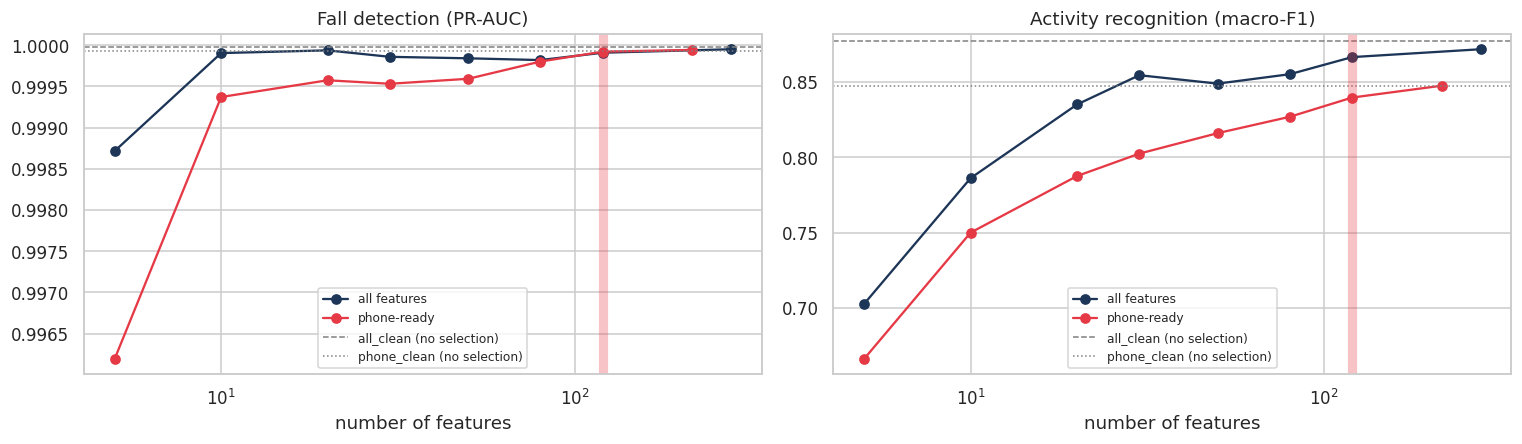

In [9]:
curve['score'] = (curve.fall_prauc + curve.activity_f1) / 2
def pick_k(name, tol=0.005):
    c = curve[curve.set == name]
    best = c.score.max()
    return int(c[c.score >= best - tol].k.min())
K_ALL, K_PHONE = pick_k('all'), pick_k('phone')
SEL_ALL, SEL_PHONE = ORDER_ALL[:K_ALL], ORDER_PHONE[:K_PHONE]
print(f'chosen: all-features model k={K_ALL} | phone model k={K_PHONE}')

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for a, met, title in [(ax[0], 'fall_prauc', 'Fall detection (PR-AUC)'), (ax[1], 'activity_f1', 'Activity recognition (macro-F1)')]:
    for name, color in [('all', '#1d3557'), ('phone', '#e63946')]:
        c = curve[curve.set == name]
        a.plot(c.k, c[met], 'o-', color=color, label={'all': 'all features', 'phone': 'phone-ready'}[name])
    for name, ls in [('all_clean', '--'), ('phone_clean', ':')]:
        a.axhline(curve.loc[curve.set == name, met].iloc[0], color='gray', ls=ls, lw=1, label=f'{name} (no selection)')
    a.axvline(K_PHONE, color='#e63946', alpha=0.3, lw=6)
    a.set_xscale('log'); a.set_xlabel('number of features'); a.set_title(title); a.legend(fontsize=8)
plt.tight_layout(); save_fig('21_k_curve'); plt.show()

## 6 · Family ablation (which kind of feature matters?)

In [10]:
groups = sorted(cat.loc[CLEAN, 'group'].unique())
abl = []
t0 = time.time()
for g in groups:
    only = [c for c in CLEAN if cat.loc[c, 'group'] == g]
    drop = [c for c in CLEAN if cat.loc[c, 'group'] != g]
    for mode, cols in [('only', only), ('without', drop)]:
        abl.append(dict(kind='family', name=g, mode=mode, n=len(cols),
                        fall_prauc=fit_eval(cols, 'fall', 20000), activity_f1=fit_eval(cols, 'activity', 20000)))
for s in ['svm', 'dyn', 'vert', 'horiz', 'gyro', 'jerk', 'tilt']:
    cols = [c for c in CLEAN if cat.loc[c, 'signal'] == s]
    abl.append(dict(kind='signal', name=s, mode='only', n=len(cols),
                    fall_prauc=fit_eval(cols, 'fall', 20000), activity_f1=fit_eval(cols, 'activity', 20000)))
abl = pd.DataFrame(abl); print(f'{time.time()-t0:.0f}s')
abl.round(4)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

564s


,kind,name,mode,n,fall_prauc,activity_f1
0,family,cross_signal,only,6,0.8257,0.4626
1,family,cross_signal,without,334,1.0000,0.8688
2,family,device_axis,only,66,0.9997,0.7901
3,family,device_axis,without,274,0.9999,0.8407
4,family,fall_dynamics,only,24,0.9996,0.7752
5,family,fall_dynamics,without,316,1.0000,0.8719
6,family,spectral,only,84,0.9909,0.7320
7,family,spectral,without,256,0.9999,0.8712
8,family,statistical,only,118,0.9997,0.8055
9,family,statistical,without,222,1.0000,0.8708


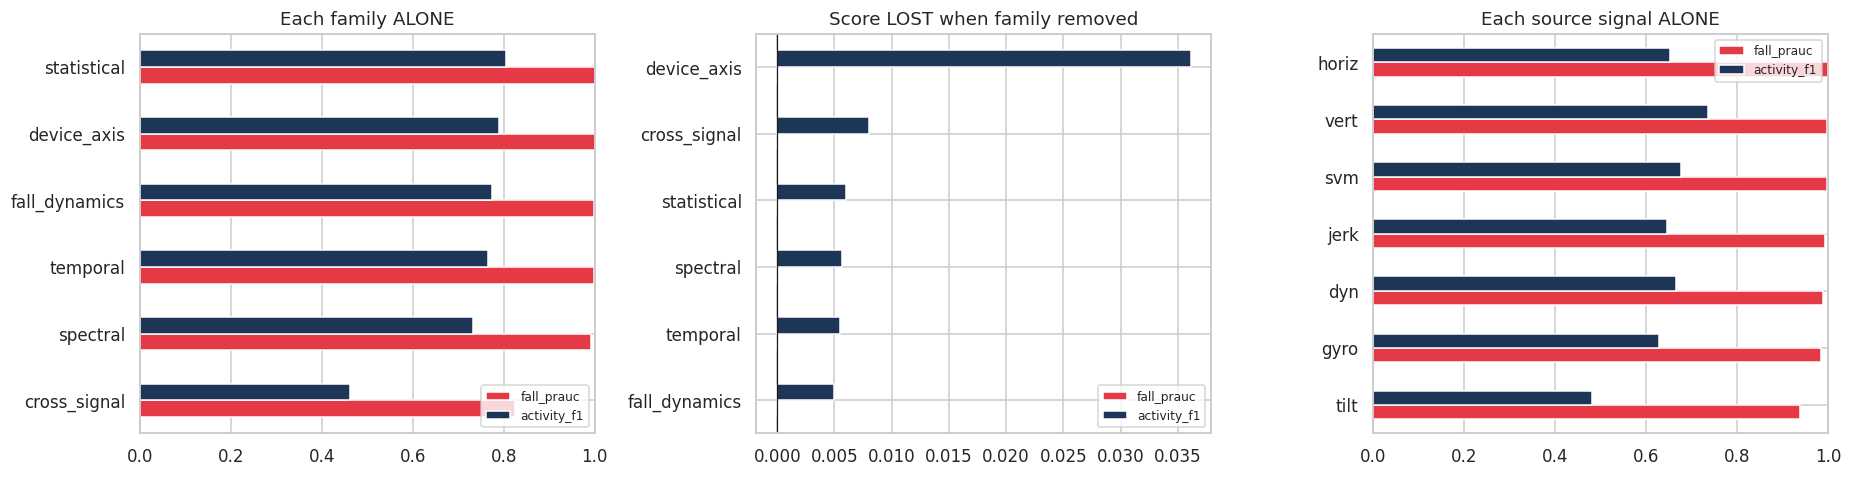

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
fo = abl[(abl.kind == 'family') & (abl['mode'] == 'only')].set_index('name')
fw = abl[(abl.kind == 'family') & (abl['mode'] == 'without')].set_index('name')
so = abl[abl.kind == 'signal'].set_index('name')
fo[['fall_prauc', 'activity_f1']].sort_values('fall_prauc').plot.barh(ax=ax[0], color=['#e63946', '#1d3557'])
ax[0].set_title('Each family ALONE'); ax[0].set_xlim(0, 1)
base_f = curve.loc[curve.set == 'all_clean', 'fall_prauc'].iloc[0]
base_a = curve.loc[curve.set == 'all_clean', 'activity_f1'].iloc[0]
drop = pd.DataFrame({'fall_prauc': base_f - fw.fall_prauc, 'activity_f1': base_a - fw.activity_f1})
drop.sort_values('activity_f1').plot.barh(ax=ax[1], color=['#e63946', '#1d3557'])
ax[1].set_title('Score LOST when family removed'); ax[1].axvline(0, color='k', lw=0.8)
so[['fall_prauc', 'activity_f1']].sort_values('fall_prauc').plot.barh(ax=ax[2], color=['#e63946', '#1d3557'])
ax[2].set_title('Each source signal ALONE'); ax[2].set_xlim(0, 1)
for a in ax: a.set_ylabel(''); a.legend(fontsize=8)
plt.tight_layout(); save_fig('22_family_ablation'); plt.show()

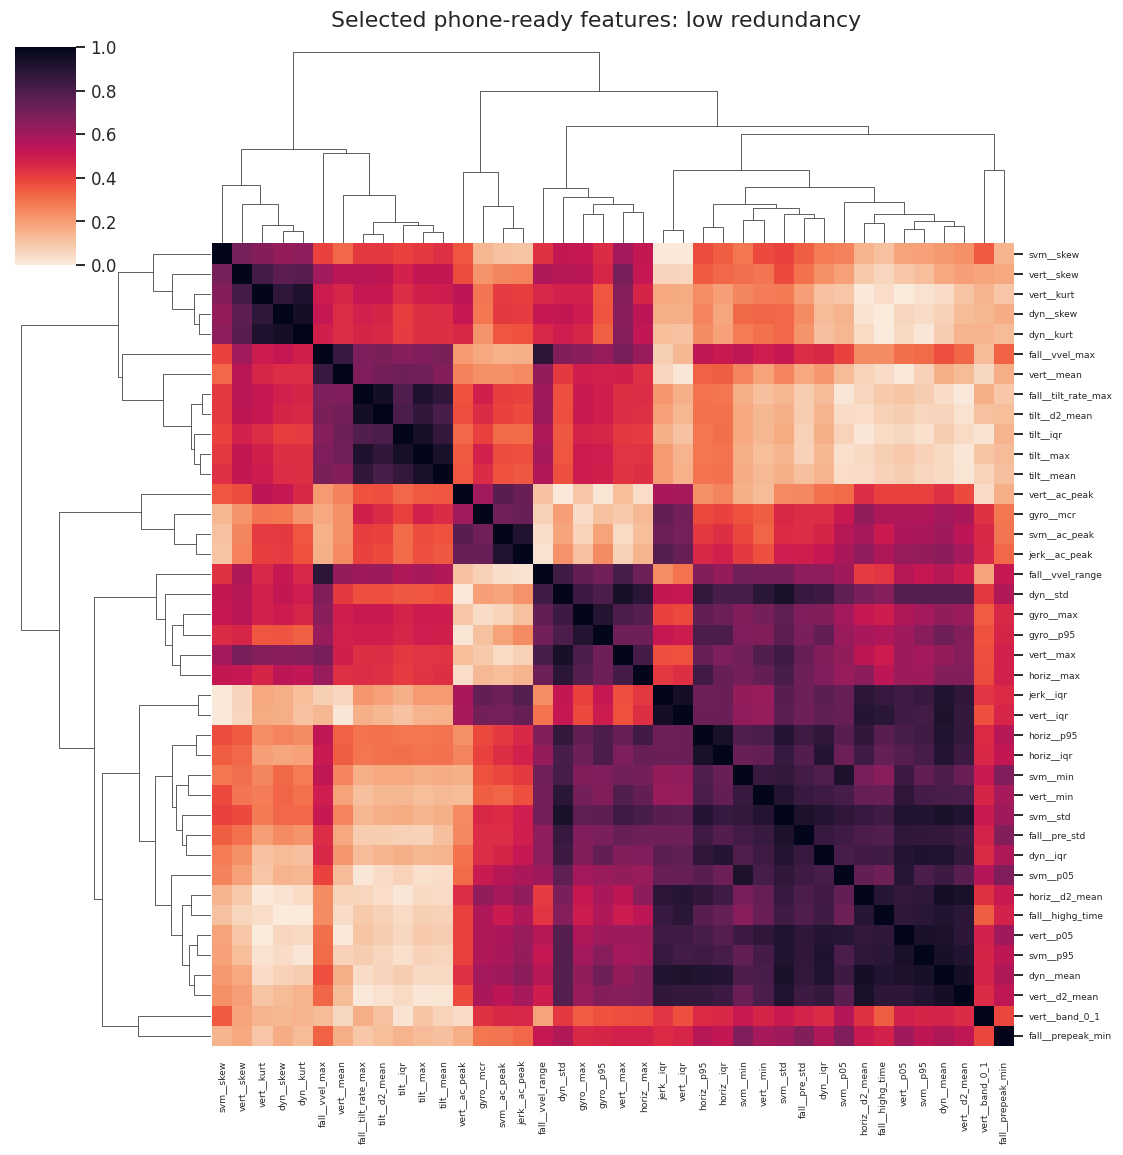

In [12]:
sel = SEL_PHONE[:40]
Cs = pd.DataFrame(C[np.ix_([pos[f] for f in sel], [pos[f] for f in sel])], index=sel, columns=sel)
g = sns.clustermap(Cs, cmap='rocket_r', vmin=0, vmax=1, figsize=(11, 11), xticklabels=True, yticklabels=True)
g.ax_heatmap.tick_params(labelsize=6); g.fig.suptitle('Selected phone-ready features: low redundancy', y=1.01)
g.savefig(f"{D['figures']}/23_selected_correlation.png", dpi=300, bbox_inches='tight'); plt.show()

## 7 · Save

In [13]:
R.to_csv(f"{D['artifacts']}/feature_ranking.csv")
curve.to_csv(f"{D['artifacts']}/feature_k_curve.csv", index=False)
abl.to_csv(f"{D['artifacts']}/feature_ablation.csv", index=False)
SELECTION = {
    'n_original': int(F.shape[1]), 'constant': const, 'duplicates': dups,
    'clean': CLEAN, 'clean_phone': [c for c in CLEAN if cat.loc[c, 'frame'] == 'invariant'],
    'corr_threshold': CORR_THR, 'order_all': ORDER_ALL, 'order_phone': ORDER_PHONE,
    'k_all': K_ALL, 'k_phone': K_PHONE, 'selected_all': SEL_ALL, 'selected_phone': SEL_PHONE,
}
json.dump(SELECTION, open(f"{D['artifacts']}/feature_selection.json", 'w'), indent=2)
print(f"unique features: {len(CLEAN)} | phone-ready: {len(SELECTION['clean_phone'])}")
print(f'selected → all-features model: {K_ALL} | phone model: {K_PHONE}')
print('top-10 phone features:', SEL_PHONE[:10])

unique features: 340 | phone-ready: 274
selected → all-features model: 120 | phone model: 120
top-10 phone features: ['fall__tilt_rate_max', 'vert__max', 'tilt__max', 'fall__vvel_range', 'tilt__mean', 'horiz__max', 'tilt__d2_mean', 'horiz__p95', 'tilt__iqr', 'dyn__std']
